# Exercise 2: SMS Spam Detection Using SVM

**Subject:** Machine Learning Lab

**Topic:** Support Vector Machines

## Aim
To develop a Support Vector Machine model that classifies SMS messages as spam or ham using text preprocessing and TF-IDF feature extraction.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)

# Load SMS spam dataset
url = (
    "https://gist.githubusercontent.com/rajvijen/"
    "51255cf4875372b904bdb812a3b85b28/raw/"
    "816dcd4cdc7553faea396186067e814487046c74/"
    "sms_spam_classification_data.csv"
)

df = pd.read_csv(url, encoding="latin-1")

print("Dataset shape:", df.shape)
display(df.head())

# Identify the message and label columns
print("Columns:", df.columns.tolist())

Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [2]:
# Clean the SMS spam dataset
df = df.iloc[:, :2].copy()
df.columns = ["label", "message"]

# Remove missing values and duplicates
df = df.dropna(subset=["label", "message"])
df = df.drop_duplicates()

# Keep only valid labels
df = df[df["label"].isin(["ham", "spam"])]

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nSample messages:")
display(df.head())

Cleaned dataset shape: (5169, 2)

Class distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Sample messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


SVM SMS Spam Detection
-----------------------------------
Training samples: 4135
Testing samples: 1034
Accuracy: 97.97%

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.98      0.85      0.91       131

    accuracy                           0.98      1034
   macro avg       0.98      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034



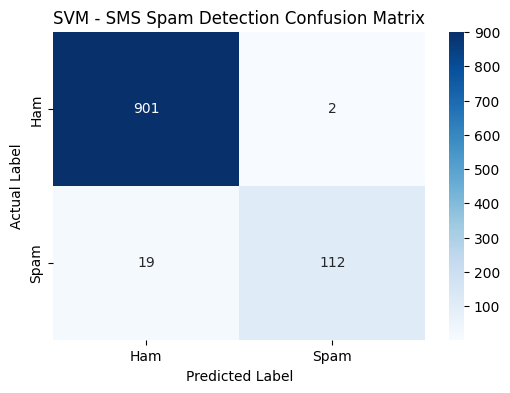

In [3]:
# Split data and train the SVM model

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Separate messages and labels
X = df["message"]
y = df["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text messages into numerical TF-IDF features
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train Support Vector Machine classifier
svm_model = SVC(kernel="linear", C=1.0)
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred = svm_model.predict(X_test_tfidf)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("SVM SMS Spam Detection")
print("-" * 35)
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM - SMS Spam Detection Confusion Matrix")
plt.show()

In [4]:
# Test the model with new SMS messages

test_messages = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hey, are we meeting for lunch today?"
]

test_features = tfidf.transform(test_messages)
predictions = svm_model.predict(test_features)

print("SMS Spam Detection Results")
print("-" * 35)

for message, prediction in zip(test_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print()

SMS Spam Detection Results
-----------------------------------
Message: Congratulations! You have won a free prize. Call now to claim.
Prediction: SPAM

Message: Hey, are we meeting for lunch today?
Prediction: HAM



## Result

The Support Vector Machine (SVM) classifier was successfully implemented to classify SMS messages as spam or ham. TF-IDF was used to convert text messages into numerical features. The model achieved an accuracy of **97.97%** on the test dataset containing 1,034 messages.

## Conclusion

The SVM model effectively classified legitimate and spam SMS messages. The confusion matrix and classification report were used to evaluate its performance. The model achieved high accuracy, although some spam messages were incorrectly classified as ham. This experiment demonstrates the usefulness of SVM and TF-IDF for text classification.